In [8]:
import pyvista as pv
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------------
# Read the final VTK files
# ------------------------------------------------------------------

base = Path("varyCb")

cb15 = pv.read(base / "Cb_1.5" / "output_3000.vti")
cb20 = pv.read(base / "Cb_2.0" / "output_3000.vti")
cb25 = pv.read(base / "Cb_2.5" / "output_3000.vti")
cb30 = pv.read(base / "Cb_3.0" / "output_3000.vti")

In [9]:
# Extract C1 and C2

cb15_C1 = cb15["C1"].reshape((40, 40))
cb15_C2 = cb15["C2"].reshape((40, 40))

cb20_C1 = cb20["C1"].reshape((40, 40))
cb20_C2 = cb20["C2"].reshape((40, 40))

cb25_C1 = cb25["C1"].reshape((40, 40))
cb25_C2 = cb25["C2"].reshape((40, 40))

cb30_C1 = cb30["C1"].reshape((40, 40))
cb30_C2 = cb30["C2"].reshape((40, 40))

In [10]:
#Commom colors

vmin1 = min(
    cb15_C1.min(),
    cb20_C1.min(),
    cb25_C1.min(),
    cb30_C1.min()
)

vmax1 = max(
    cb15_C1.max(),
    cb20_C1.max(),
    cb25_C1.max(),
    cb30_C1.max()
)

vmin2 = min(
    cb15_C2.min(),
    cb20_C2.min(),
    cb25_C2.min(),
    cb30_C2.min()
)

vmax2 = max(
    cb15_C2.max(),
    cb20_C2.max(),
    cb25_C2.max(),
    cb30_C2.max()
)

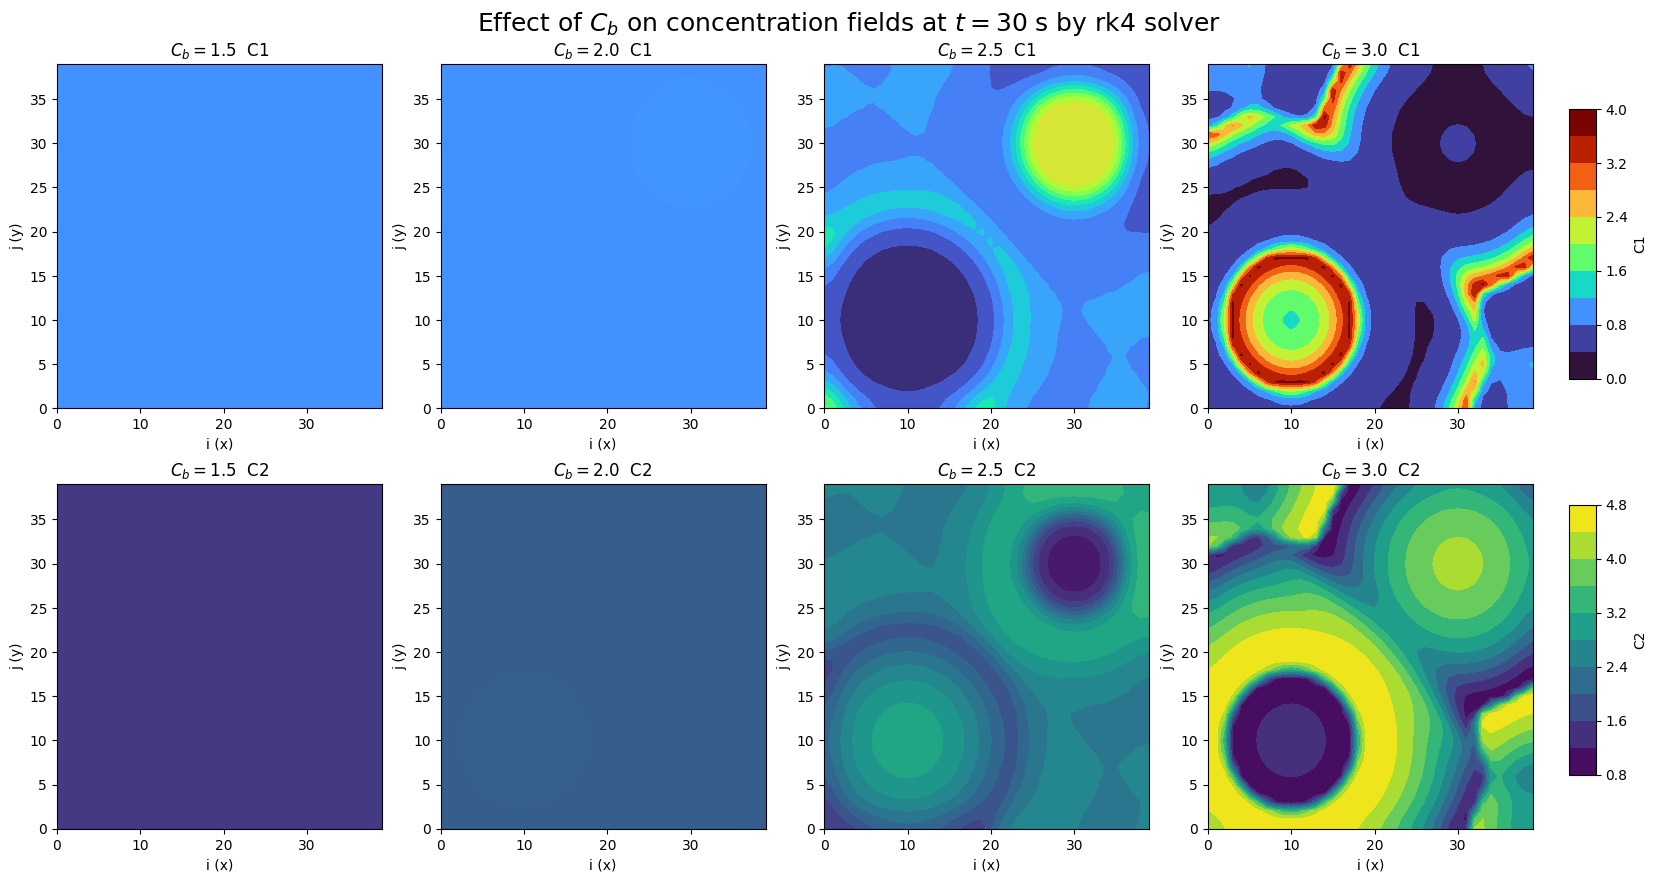

In [12]:
# Create figure
fig, axs = plt.subplots(2, 4, figsize=(18, 9))

fig.suptitle(
    r"Effect of $C_b$ on concentration fields at $t=30$ s by rk4 solver",
    fontsize=18
)

titles = [
    r"$C_b=1.5$",
    r"$C_b=2.0$",
    r"$C_b=2.5$",
    r"$C_b=3.0$"
]

C1_list = [
    cb15_C1,
    cb20_C1,
    cb25_C1,
    cb30_C1
]

C2_list = [
    cb15_C2,
    cb20_C2,
    cb25_C2,
    cb30_C2
]

for i in range(4):

    im1 = axs[0, i].contourf(
        C1_list[i],
        levels=10,
        cmap="turbo",
        vmin=vmin1,
        vmax=vmax1
    )

    axs[0, i].set_title(titles[i] + "  C1")
    axs[0, i].set_xlabel("i (x)")
    axs[0, i].set_ylabel("j (y)")

    im2 = axs[1, i].contourf(
        C2_list[i],
        levels=10,
        cmap="viridis",
        vmin=vmin2,
        vmax=vmax2
    )

    axs[1, i].set_title(titles[i] + "  C2")
    axs[1, i].set_xlabel("i (x)")
    axs[1, i].set_ylabel("j (y)")


# Leave some room on the right
plt.subplots_adjust(right=0.88)
# Create separate axes for the colorbars
cax1 = fig.add_axes([0.90, 0.57, 0.015, 0.30])  # [left, bottom, width, height]
cax2 = fig.add_axes([0.90, 0.13, 0.015, 0.30])

#Draw the colorbars
cbar1 = fig.colorbar(im1,cax=cax1)
cbar1.set_label("C1")

cbar2 = fig.colorbar(im2,cax=cax2)
cbar2.set_label("C2")

plt.subplots_adjust(
    left=0.06,
    right=0.88,
    bottom=0.07,
    top=0.92,
    wspace=0.18,
    hspace=0.22
)

#Save the figure
plt.savefig("Effect of Cb variation on concentration fields using RK4 solver.png", dpi=300,bbox_inches="tight")

plt.show()
